# NLSE for the gifted amateur

The goal of this presentation is to introduce the detailed functionality of `NLSE` which is the main workhorse of the numerical simulations we do in the group.
This presentation will be centered around the following plan:
- Introduction
- Split-step spectra schemes
- `NLSE` main class
- First example: turbulence experiment
- Second example: broadcasting
- Third example: callbacks
- Conclusion


## Introduction

Due to the high dimensional parameter space involved in our fluids of light experiments , it is often useful to resort to numerical campaigns to accelerate grid searches, or get to otherwise inaccessible observables.

It is **paramount to perfectly understand** the numerical limitations, and mathematical particularities of the chosen solver to avoid potential pitfalls of *unphysical results* or *convergence issues*.

**Before looking at any physical observables**, you should be absolutely sure that **your modelling encapsulates the physics you want to observe** !

The equations these solvers integrate, and the units each parameter is in,
are set out on the [Physics Background](physics_problem.md) page.

This presentation is meant as a detailed guide to use `NLSE` but also as a zen guide towards numerical experiments.

## Split-step spectral schemes


Let's first present the crux of this projet: split-step spectral schemes.

We'll start with a very general NLSE type equation:

$$
i\frac{\partial\psi}{\partial z} = -\frac{1}{2k_0}\nabla^2\psi + V\psi + g|\psi|^2\psi
$$

How might we go about solving it ?

### Split-step

If we first go to a Euler-type expansion:

$$
\frac{\mathrm{d}\psi}{\psi} = \left(i \frac{1}{2k_0}\nabla^2 -iV -i g|\psi|^2\right)\mathrm{d}z
$$

Integrating over a "small enough" $\delta z$:

$$
\psi(z+\delta z) = e^{\left(i \frac{1}{2k_0}\nabla^2 -iV -i g|\psi|^2\right)\delta z}\psi(z)
$$

Now, depending on needs, you might use more involved differentiation formulas like Runge-Kutta or something else ...
You might rewrite this as follows:

$$
\psi(z+\delta z) = e^{(L+N)\delta z}\psi(z)
$$
where $L=i \frac{1}{2k_0}\nabla^2$ and $N=-iV -i g|\psi|^2$.

Now the most careless of you might think "wait, this is easy, we can just expand the exponential into a product !"

<center>WRONG !</center>

You have to keep in mind that we are actually working with matrices $L_{ij}$ / $N_{ij}$ i.e everything is happening on a discrete grid $r_{ij} = (x_i, y_j)$.

We thus can expand the exponential using Baker-Hausdorff, at leading order of $\delta z$: this is the split-step part.

The next question is then how can we efficiently compute the two exponentials ? 

### Spectral

The trick is to compute the Laplacian in Fourier space since $\nabla \iff \times i\mathbf{k}$ 

$$
e^{i\frac{1}{2k_0}\nabla^2} = \mathcal{F}^{-1}\left(e^{-i\frac{\mathbf{k}^2}{2k_0}}\right)
$$

We can finally put everything back together:

$$
\psi(z+\delta z) = e^{-iV-ig|\psi|^2\delta z}\mathcal{F}^{-1}\left(e^{-i\frac{\mathbf{k}^2}{2k_0}\delta z}\mathcal{F}\left( \psi(z)\right)\right)
$$

This is the so-called **split-step spectral method**, accurate with a $O(\delta z)$ error.

By "leap-frogging" the non-linear step (i.e applying half of it before the linear step, and half of it after), we can get a $O(\delta z^3)$ error.

### Remarks about complexity

We see that we have 2 FFT and 2 matrix multiplication per solver cycle, or 2FFT and 3 matrix multiplication in the case of the leapfrog scheme.

The good thing about FFT's is that they can be carried out with $N\mathrm{log}(N)$ complexity.

Matrix multiplications on the other hand cost us $O(N^2)$. 

This means that we will quickly be limited by matrix multiplications, and this means that switching between `complex64` and `complex128` precision will have a quadratic impact on performance.

This is important to keep in mind when trying to optimize performance with these solvers.
### Which of these you get, and how to ask for it

The three schemes above are what `splitting` selects, and they are named for
themselves rather than for how many applications they take:

| `splitting` | what it does | error |
|---|---|---|
| `"lie"` | one linear step, one non-linear step | $O(\delta z)$ |
| `"strang"` | the leap-frog above: half a non-linear step either side | $O(\delta z^3)$ |
| `"yoshida"` | three Strang steps composed, the middle one backwards | $O(\delta z^5)$ |

```python
E_out = simu.out_field(E, L, splitting="strang", verbose=False, plot=False)
```

Two warnings the solver will give you rather than let you waste time:

- `"yoshida"` on a `complex64` field costs three transform pairs per step to
  buy an order that single-precision round-off has already spent. Give it a
  `complex128` field or use `"strang"`.
- `"yoshida"` in a **lossy** medium runs its middle sub-step backwards, which
  amplifies rather than decays. The composition is still fourth order, but the
  intermediate field is not physical and can overflow.

## `NLSE` main class

We'll start with the main class and then expose all of the internals such as to make the inner workings of the class very clear. 

Let's start with the parameters needed to run a simulation:
- `N`: the number of grid points
- `n2`: the non-linear index of refraction $n_2$ in $m^2/W$
- `window`: the physical size of the computational window in $m$
- `power`: the total power of the beam in $W$
- `Isat`: the saturation intensity of the medium in $W/m^2$
- `L`: the length of the non-linear medium in $m$
- `alpha`: the linear absorption coefficient in $m^{-1}$
- `backend`: whether to solve the equation using the GPU or the CPU

Since most of the computations required are elementwise matrix multiplications and FFT's, they are very well suited to GPU computation. 
Thus we provide either a CPU (to run on all machines), or a GPU backend.
Thus most of the performance of `NLSE` is obtained with the GPU backend.

An instance of the simulation can be initialized as follows:

In [1]:
from NLSE import NLSE

N = 1024
n2 = -1.6e-9
window = 12e-3
power = 1.05
Isat = 10e4
L = 20e-2
alpha = 20
backend = "CPU"  # no GPU on the mac ...
simu = NLSE(
    alpha=alpha,
    power=power,
    window=window,
    n2=n2,
    V=None,
    L=L,
    NX=N,
    NY=N,
    Isat=Isat,
    backend=backend,
)

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


Behind the curtain, the `__init__` function works as follows:

```python
def __init__(
        self,
        alpha: float,
        power: float,
        window: float,
        n2: float,
        V: np.ndarray,
        L: float,
        NX: int = 1024,
        NY: int = 1024,
        Isat: float = np.inf,
        nl_length: float = 0,
        wvl: float = 780e-9,
        backend: str = __BACKEND__,
    ) -> object:
        """Instantiates the simulation.
        Solves an equation : d/dz psi = -1/2k0(d2/dx2 + d2/dy2) psi + k0 dn psi +
          k0 n2 psi**2 psi
        Args:
            alpha (float): alpha
            power (float): Power in W
            window (float): Computational window in the transverse plane in m.
            n2 (float): Non linear coeff in m^2/W
            V (np.ndarray): Potential.
            L (float): Length in m of the nonlinear medium
            NX (int, optional): Number of points in the x direction. Defaults to 1024.
            NY (int, optional): Number of points in the y direction. Defaults to 1024.
            Isat (float): Saturation intensity in W/m^2
            nl_length (float): Non local length in m
            wvl (float): Wavelength in m
            backend (str, optional): "GPU" or "CPU". Defaults to __BACKEND__.
        """
        # listof physical parameters
        self.backend = backend
        if self.backend == "GPU" and self.__CUPY_AVAILABLE__:
            self._kernels = kernels_gpu
        else:
            self.backend = "CPU"
            self._kernels = kernels_cpu
        self.n2 = n2
        self.V = V
        self.wl = wvl
        self.k = 2 * np.pi / self.wl
        self.L = L  # length of the non linear medium
        self.alpha = alpha
        self.power = power
        self.I_sat = Isat
        # number of grid points in X (even, best is power of 2 or low prime factors)
        self.NX = NX
        self.NY = NY
        self.window = window
        Dn = self.n2 * self.power / self.window**2
        z_nl = 1 / (self.k * abs(Dn))
        if isinstance(z_nl, np.ndarray):
            z_nl = z_nl.min()
        # delta_z is chosen per run, in out_field
        # transverse coordinate
        self.X, self.delta_X = np.linspace(
            -self.window / 2,
            self.window / 2,
            num=NX,
            endpoint=False,
            retstep=True,
            dtype=np.float32,
        )
        self.Y, self.delta_Y = np.linspace(
            -self.window / 2,
            self.window / 2,
            num=NY,
            endpoint=False,
            retstep=True,
            dtype=np.float32,
        )
        # define last axes for broadcasting operations
        self._last_axes = (-2, -1)

        self.XX, self.YY = np.meshgrid(self.X, self.Y)
        # definition of the Fourier frequencies for the linear step
        self.Kx = 2 * np.pi * np.fft.fftfreq(self.NX, d=self.delta_X)
        self.Ky = 2 * np.pi * np.fft.fftfreq(self.NY, d=self.delta_Y)
        self.Kxx, self.Kyy = np.meshgrid(self.Kx, self.Ky)
        self.propagator = None
        self.plans = None
        self.nl_length = nl_length
``````

In order to solve the equation we need to do Fourier transforms and matrix multiplications, thus we want to optimize both of these operations.

This is carried out using two tricks:
- Careful planing of the FFT's and caching of the plans
- Optimize as kernel operations all of the elementwise operations needed for matrix multiplications and exponential calculation

The planning is done by the `_build_fft_plan` functions.
The kernels are defined in `kernels_cpu.py` and `kernels_gpu.py`.
Numba and Cupy are leveraged in order to just-in-time compile these operations to such that subsequent evaluations are greatly accelerated, while making the code easy to read and modify.

The zen of all of these operations is to try to do as much as possible *in place* meaning modifying the field array itself, rather than returning a result that implies making a copy. 
This is more memory efficient, as well as being (**in general**) faster.

As with anything, we are **scientists** so everything should be **measured** ! This means that if at some point, for some reason, you are not happy with the performance of something (i.e you have measured that it is the limiting factor), you should focus your efforts on this single function, and **properly profiling it**. 
For this, there are a lot of tools available on GPU or CPU. 

For a good first overview, I recommend [`scalene`](https://github.com/plasma-umass/scalene) since it is both accurate and low overhead, as well as having a nice graphical output.
For GPU, if you want to get into the nitty gritty of what the GPU is doing, you can use [`nsys`](https://developer.nvidia.com/nsight-systems) for general purpose profiling or [`ncu`](https://developer.nvidia.com/nsight-compute) for kernel profiling, allowing you to inspect the actual assembly instructions getting executed.

I cannot stress this enough: **if you feel like your code is running slow for any reason, don't infer anything ! PROFILE !**

The main loop is carried out in the `out_field` function, that calls the `split_step` routine. 

`split_step` evolves the field from a single step $\delta z$.

Most of the `out_field` function is simply boilerplate code in order to handle the various use cases allowed by the different function arguments like normalizing the field to its SI units, sending the arrays to the GPU etc ...


### Choosing $\delta z$

The step is an argument of `out_field`, not a property of the solver:

```python
E_out = simu.out_field(E, L, delta_z=1e-4, verbose=False, plot=False)
```

Leave it out and the solver picks one from the field itself, aiming at a fixed
phase per step rather than at whatever a stability limit allows. That is
usually what you want: the step then tracks the physics, so a stronger
non-linearity shortens it without you noticing.

If the field changes character during the propagation — as it does in the
turbulence example below, which starts smooth and does not stay that way —
the step can follow it:

```python
from NLSE import adapt_delta_z

E_out = simu.out_field(E, L, callback=adapt_delta_z, verbose=False, plot=False)
```

There is also `adapt_delta_z_to_error`, which measures the error of the step
it just took instead of inferring it from the field.

## First example: turbulence experiment

In this numerical experiment, we will consider the scenario of two conterstreaming components colliding each other leading to the emergence of a turbulent pattern.

We thus need to define two counter streaming components.

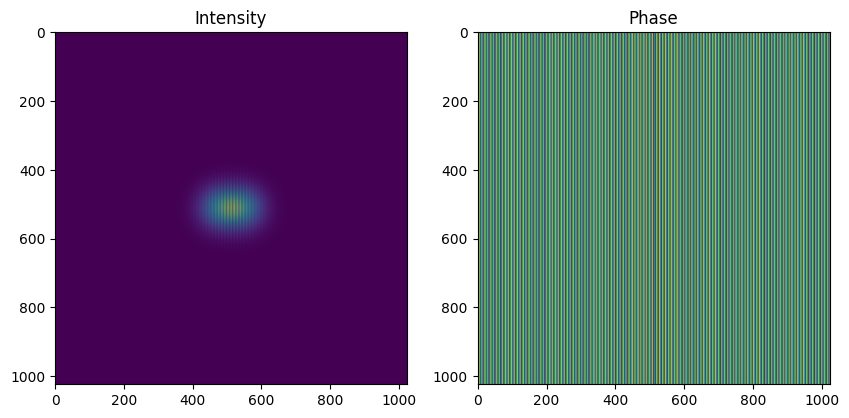

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# Define two counterstreaming components
w0 = 1e-3
kx = 2 * np.pi * 1e4
# make the two components collide in the middle of the cell, so shift each components according
# to the angle
offset = simu.L / 2 * np.tan(kx / simu.k)
E0 = np.exp(-(np.hypot(simu.XX - offset / 2, simu.YY) ** 2) / w0**2) * np.exp(
    -1j * kx * simu.XX
)
E1 = np.exp(-(np.hypot(simu.XX + offset / 2, simu.YY) ** 2) / w0**2) * np.exp(
    1j * kx * simu.XX
)
E = E0 + E1
E = E.astype(np.complex64)
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].set_title("Intensity")
ax[0].imshow(np.abs(E) ** 2)
ax[1].set_title("Phase")
ax[1].imshow(np.angle(E))

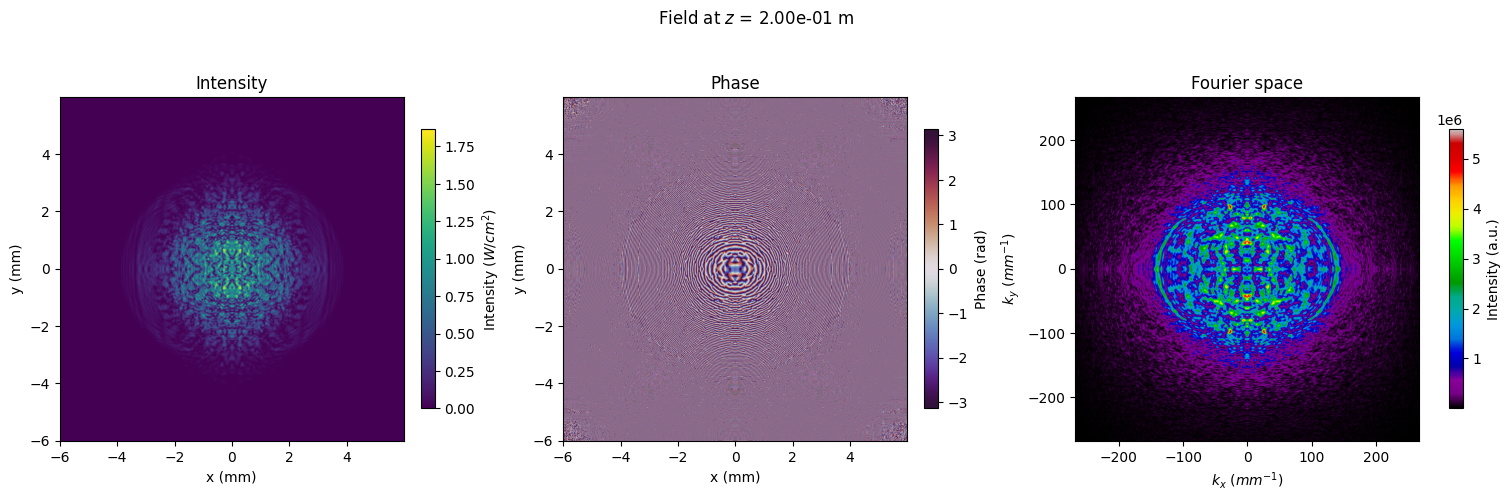

array([[-9.5781981e-04+6.2736543e-03j, -2.1315987e-04+2.3380285e-03j,
         4.3718321e-03+6.5164743e-03j, ...,
        -1.0567465e-03-4.7152466e-04j,  6.2525109e-03-1.2327419e-03j,
        -2.7224192e-04+8.6955413e-05j],
       [-3.7271710e-04-1.9070633e-04j, -7.3912102e-05+2.0851432e-03j,
        -1.1778289e-03-6.8986614e-04j, ...,
        -2.9760192e-03+5.4164883e-03j,  3.0911458e-03+9.7008888e-04j,
         2.8885874e-05+4.0042372e-03j],
       [-1.2821158e-03-2.5574421e-04j,  1.3674633e-04-6.7928256e-03j,
         2.6994890e-03-2.3652765e-03j, ...,
        -2.1313010e-03-1.9398800e-03j, -1.3578743e-03+4.2342520e-03j,
        -2.9984133e-03-4.4478886e-03j],
       ...,
       [-1.1281571e-03-2.4561926e-03j, -1.0089806e-03+8.1720221e-04j,
         4.6983319e-03-2.9120832e-03j, ...,
         1.0269672e-03+4.7227805e-03j,  7.9123472e-04+6.1984020e-03j,
        -3.8557579e-03+3.4803010e-03j],
       [ 7.2661374e-04+1.0953404e-03j, -2.3290948e-03-1.4442937e-03j,
         7.0094997e-03

In [3]:
# Propagate the field and plot the result
simu.out_field(E, L, plot=True, verbose=False)

### A note on loss

This example is lossy: `alpha = 20` over 20 cm, so the beam ends at a small
fraction of the intensity it started with. That matters more than it looks.

A real-space step applies $e^{-\alpha s\delta z + ig|A|^2 s\delta z}$ with
$|A|^2$ read once, on entry. That is exact only while the step *preserves*
$|A|^2$ — true of a pure rotation, and false the moment there is loss, because
the amplitude decays inside the step while the interaction goes on turning the
phase at the rate it began with. Frozen like that, the sub-step is
$O(\delta z^2)$ locally and first order over a run, and it drags whatever
composition is wrapped around it down with it: Strang and Yoshida both came out
**first order** on this problem.

Since 4.0.0 the step is solved rather than frozen, which on exactly this
turbulence problem is worth about 69x in accuracy for Strang and 7000x for
Yoshida at matched cost. Nothing about how you call it changes, and a lossless
run is unchanged to the bit.

## Second example: broadcasting

Now let's say you would want to simulate several realizations of this turbulent regime, or explore it for different initial velocities. 

You could use a `for` loop of course, but this would not optimally use the GPU since a single realization does not saturate the compute bandwidth.

The solution is to propagate a *tensor* of size $N_{real} \times N_y \times N_x$.

In [4]:
# Create the noise for the inital state
N_real = 4
noise = np.random.normal(size=(N_real, N, N), scale=1e-3)

In order for the computation to "work", the dimensions must be compatible i.e **broadcastable**.

This means that the last dimensions must match. This is intricately linked to the fact that arrays are stored in **column-major** order i.e the fast axis is the last one.  

In [5]:
# use broadcasting to add the noise to the field
E_noisy = E + noise

/var/folders/s8/1kcsxfs556s4brcnjgnhqpx00000gn/T/ipykernel_53675/1925656159.py:1: UserWarning: splitting='lie' on a complex128 field: with the round-off floor out of the way the splitting error is what is left, and splitting='yoshida' reaches a given accuracy for much less work.
  E_out = simu.out_field(E_noisy, L, plot=False, verbose=False)


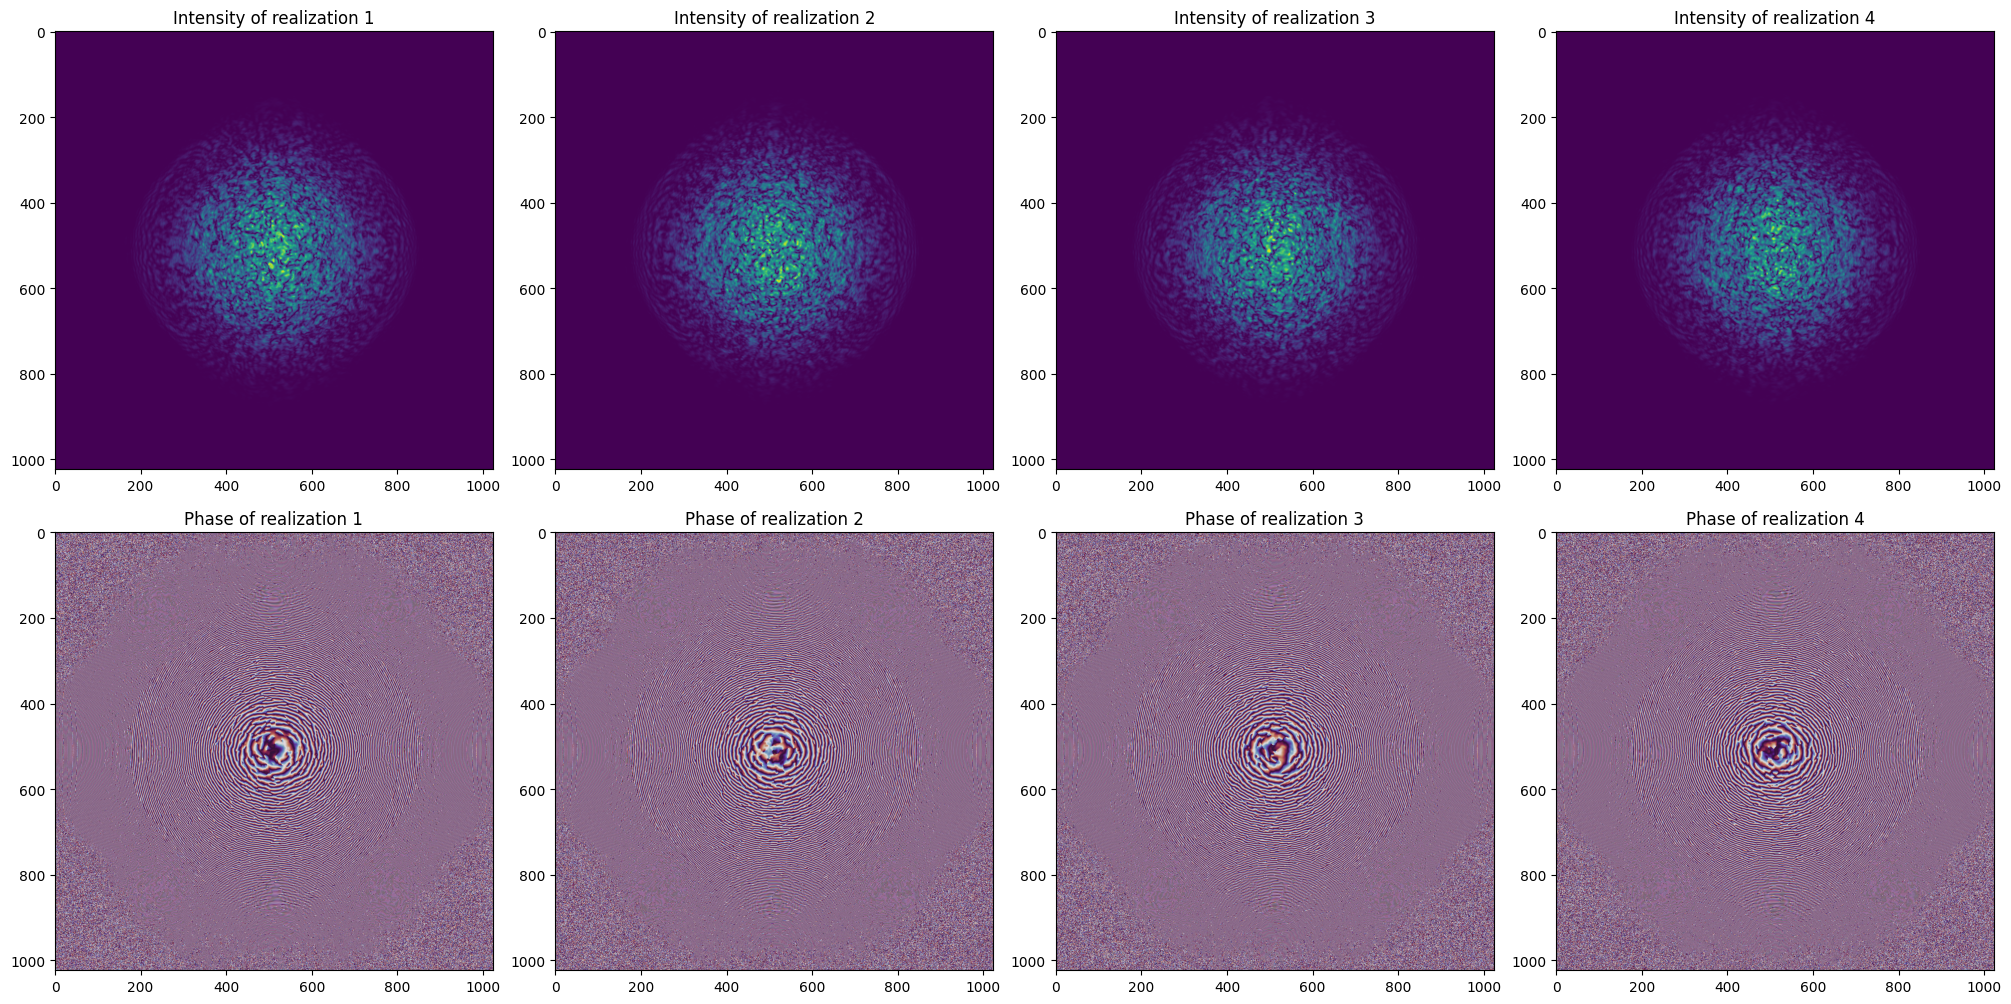

In [6]:
E_out = simu.out_field(E_noisy, L, plot=False, verbose=False)
fig, ax = plt.subplots(2, 4, figsize=(20, 10), layout="constrained")
for j in range(N_real):
    ax[0, j].imshow(np.abs(E_out[j]) ** 2)
    ax[1, j].imshow(np.angle(E_out[j]), cmap="twilight_shifted")
    ax[0, j].set_title(f"Intensity of realization {j + 1}")
    ax[1, j].set_title(f"Phase of realization {j + 1}")
plt.show()

This broadcasting mechanism holds for all the physical parameters of the simulation except for the parameters involved in the spatial grid (`window`,`NX`, `NY`).

For instance if you want to simulate for different powers, you can set the `power` attribute to a $N_{powers}$ array as follows:

/var/folders/s8/1kcsxfs556s4brcnjgnhqpx00000gn/T/ipykernel_53675/2899671297.py:4: UserWarning: splitting='lie' on a complex128 field: with the round-off floor out of the way the splitting error is what is left, and splitting='yoshida' reaches a given accuracy for much less work.
  E_out = simu.out_field(E_noisy, L, plot=False, verbose=False)


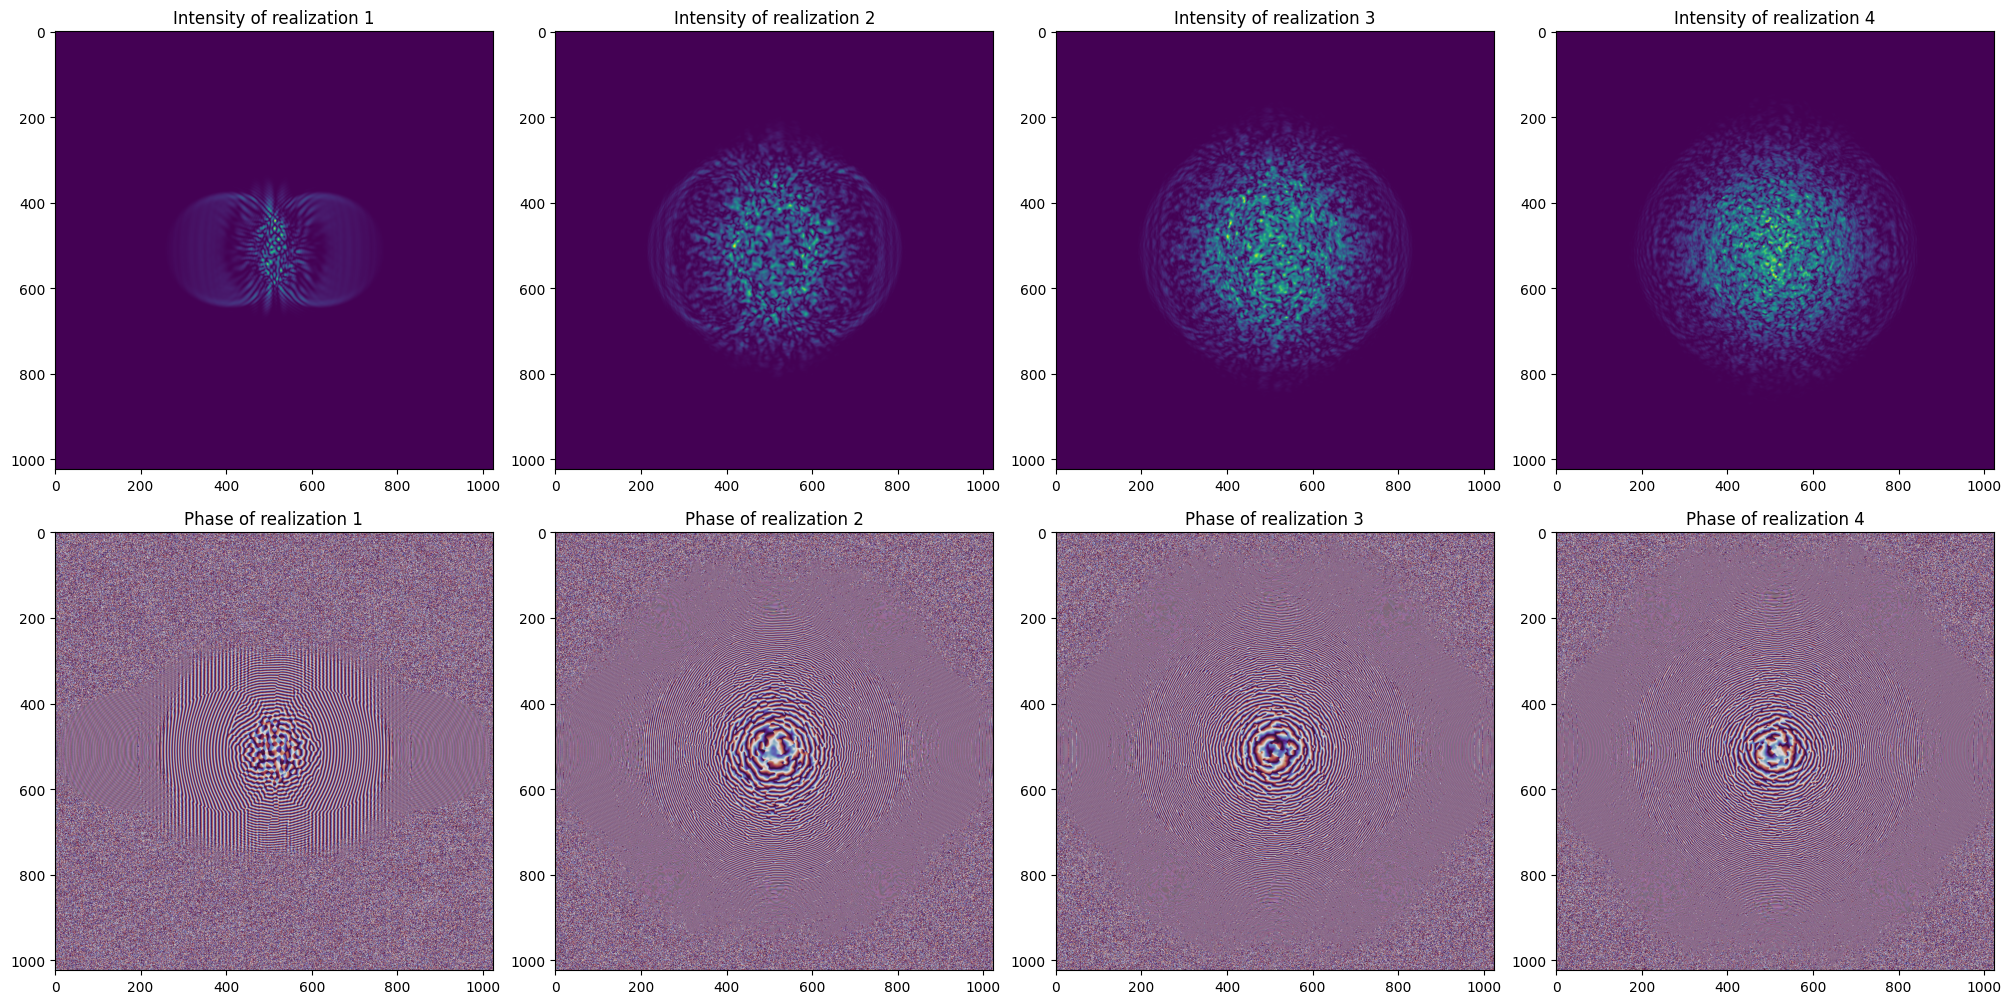

In [7]:
# powers from 100mW to 1W
powers = np.linspace(100e-3, 1, 4)
simu.power = powers
E_out = simu.out_field(E_noisy, L, plot=False, verbose=False)
fig, ax = plt.subplots(2, 4, figsize=(20, 10), layout="constrained")
for j in range(N_real):
    ax[0, j].imshow(np.abs(E_out[j]) ** 2)
    ax[1, j].imshow(np.angle(E_out[j]), cmap="twilight_shifted")
    ax[0, j].set_title(f"Intensity of realization {j + 1}")
    ax[1, j].set_title(f"Phase of realization {j + 1}")
plt.show()

## Example 3: callbacks

So far, we focused on the final state of the field after evolution through the cell. However we are often interested in following what goes on inside of the cell. 

To this end, the most efficient strategy is to periodically call a function (a callback) during the main loop, such as to extract samples of the field, or compute some observables.

This is implemented through the `callback` and `callback_args` arguments of the `out_field` function. 

In [8]:
def callback(simu: NLSE, A: np.ndarray, z: float, i: int, *callback_args) -> None:
    """Do nothing, as an illustration of the callback signature.

    Parameters
    ----------
    simu : NLSE
        The simulation object.
    A : np.ndarray
        The field at the current step.
    z : float
        The current propagation distance in metres.
    i : int
        The main loop index.
    """
    pass

To avoid hindering the solver performance, this callback should never transfer memory from the GPU to the CPU, and not involve too complicated operations (or not get called too often).

For instance, let us say we want to monitor the evolution of the vortex pattern through the cell by capturing 50 samples of the field:

In [9]:
simu.power = 1.05
N_samples = 50
z_samples = np.zeros(N_samples + 1)  # +1 to account for the 0th step
E_samples = np.zeros((N_samples + 1, N, N), dtype=np.complex64)
delta_z = L / 1000  # divides L: exactly 1000 steps
N_steps = round(L / delta_z)
save_every = N_steps // N_samples

In [10]:
def callback_sample(
    simu: NLSE,
    A: np.ndarray,
    z: float,
    i: int,
    E_samples: np.ndarray,
    z_samples: np.ndarray,
) -> None:
    """Save the field every ``save_every`` steps.

    Parameters
    ----------
    simu : NLSE
        The simulation object.
    A : np.ndarray
        The field at the current step.
    z : float
        The current propagation distance in metres.
    i : int
        The main loop index.
    E_samples : np.ndarray
        The array the samples are written into.
    z_samples : np.ndarray
        The distances they were taken at.
    """
    if i % save_every == 0:
        E_samples[i // save_every] = A
        z_samples[i // save_every] = z


simu.out_field(
    E_noisy[0],
    L,
    delta_z=delta_z,  # the step the sampling above was sized for
    callback=callback_sample,
    callback_args=(E_samples, z_samples),
    verbose=False,
)

/var/folders/s8/1kcsxfs556s4brcnjgnhqpx00000gn/T/ipykernel_53675/3321890050.py:31: UserWarning: splitting='lie' on a complex128 field: with the round-off floor out of the way the splitting error is what is left, and splitting='yoshida' reaches a given accuracy for much less work.
  simu.out_field(


array([[-2.17952018-1.07863632j,  0.72091523-1.07885072j,
        -2.33348461+2.53297723j, ..., -2.15830172+1.79830201j,
        -0.44742632+0.63060972j, -2.42767808-1.37672332j],
       [-0.59696114+0.12017884j, -0.34505473+0.66581785j,
        -1.37920178-0.84430099j, ..., -1.22744885+0.57450974j,
        -1.39480471+2.20044227j, -0.54666306-0.49344419j],
       [-1.15948942+2.51893113j,  1.07744752+0.90012242j,
         0.06204322+1.86111431j, ...,  0.94585532+1.52447867j,
         1.71169266+1.00972345j,  2.18637301-2.23991672j],
       ...,
       [ 1.98666232+0.92599783j,  1.03129187-0.68259642j,
         1.36285996-0.0895895j , ...,  0.81872322+1.82173934j,
        -0.84131544-0.3043461j , -1.63923603+2.36029429j],
       [-1.58107377-2.78616436j,  1.75004643-0.28854053j,
         2.22385729+1.08214282j, ...,  1.64620603+0.25331241j,
        -1.04722709-2.95145301j,  1.82727227-1.7673562j ],
       [-0.16688858-0.16873701j, -1.99686205+3.53038461j,
        -0.15801947-1.64358801

Now let's plot the results

Animation movie is 78386013 bytes, exceeding the limit of 20971520.0. If you're sure you want a large animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB).


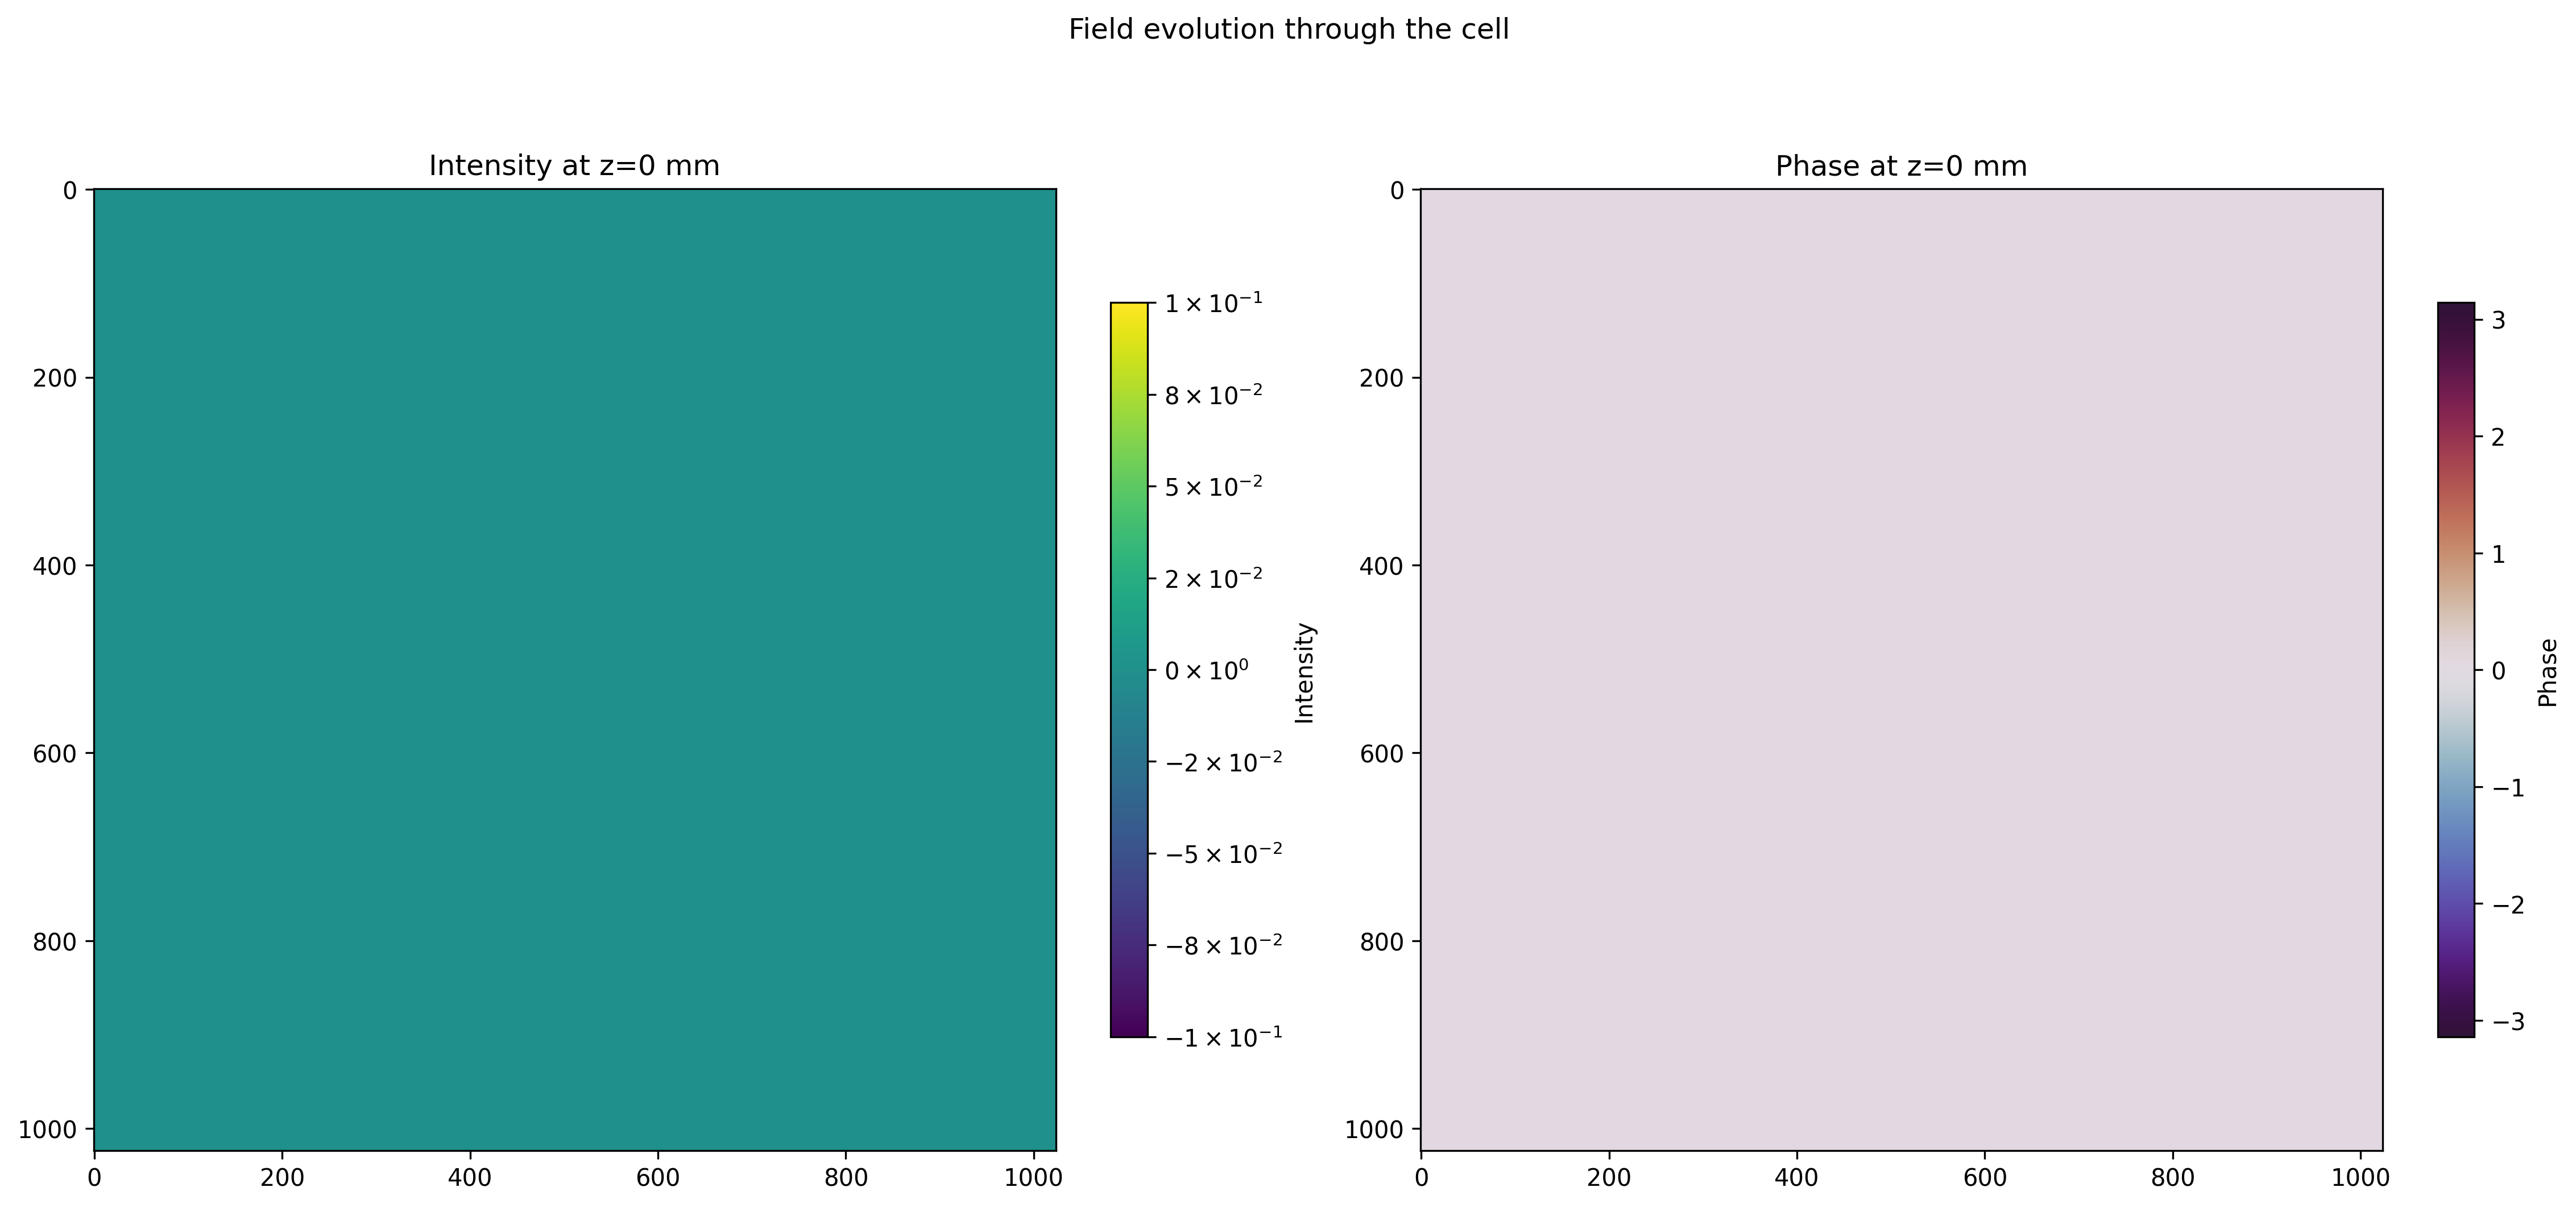

In [11]:
import matplotlib.ticker as ticker
from IPython.display import HTML
from matplotlib import animation


def fmt(x, pos) -> str:
    a, b = f"{x:.0e}".split("e")
    b = int(b)
    return rf"${a} \times 10^{{{b}}}$"


rho = np.abs(E_samples) ** 2
phi = np.angle(E_samples)
fig, ax = plt.subplots(1, 2, figsize=(15, 7.5), layout="constrained", dpi=300)
im0 = ax[0].imshow(rho[0])
im1 = ax[1].imshow(phi[0], cmap="twilight_shifted")
fig.colorbar(
    im0, ax=ax[0], label="Intensity", format=ticker.FuncFormatter(fmt), shrink=0.6
)
fig.colorbar(im1, ax=ax[1], label="Phase", shrink=0.6)
fig.suptitle("Field evolution through the cell")
ax[0].set_title("Intensity at z=0 mm")
ax[1].set_title("Phase at z=0 mm")


def animate(i: int):
    im0.set_data(rho[i])
    im1.set_data(phi[i])
    ax[0].set_title(f"Intensity at z={z_samples[i] * 1e3:.0f} mm")
    ax[1].set_title(f"Phase at z={z_samples[i] * 1e3:.0f} mm")
    im0.set_clim(0, np.max(rho[i]))
    im1.set_clim(-np.pi, np.pi)
    return im0, im1


anim = animation.FuncAnimation(
    fig, animate, frames=N_samples + 1, interval=150, blit=True
)
HTML(anim.to_html5_video())

## Where to go next

- **Physical Validation** — the closed-form solutions the solvers are checked
  against, and what each one would catch. Worth a look before trusting any of
  this on a problem of your own.
- **Numerical Methods** — the step-size limits, the splittings and the
  adaptive steppers in more detail.
- **Backends** — what each of `"CPU"`, `"CUPY"`, `"CL"` and `"MLX"` supports,
  and which ones can broadcast a batch.